# Applications — Exercise 4: Color Quantization

**Instructor's task:** Load your own photo with `plt.imread("your_photo.jpg")` and find the smallest `k` that still looks right to you.

In color quantization, we represent image colors using only `k` representative colors. We use K-Means to group similar pixel colors. The best minimum `k` is subjective, so inspect the results for your own photo and choose the smallest one whose visual quality you consider acceptable.

**Before running:** Put your image file in the same folder as this notebook and name it `your_photo.jpg` (or change the filename in Cell 2).

## Cell 1 — Import the Required Libraries

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans

## Cell 2 — Load and Display Your Photo

Use `plt.imread()` as specified in the exercise. The code below supports grayscale, RGB, and RGBA images.

Image shape: (869, 736, 3)


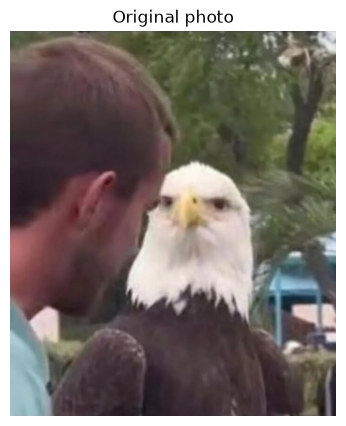

In [9]:
image = plt.imread("Eagle.jpg")

# Convert grayscale to RGB if necessary
if image.ndim == 2:
    image = np.repeat(image[:, :, np.newaxis], 3, axis=2)

# Remove the alpha channel if the image has one
if image.ndim == 3 and image.shape[2] == 4:
    image = image[:, :, :3]

# K-Means expects numeric pixel values; scale integer images to [0, 1]
if np.issubdtype(image.dtype, np.integer):
    image = image.astype(np.float32) / np.iinfo(image.dtype).max
else:
    image = image.astype(np.float32)

image = np.clip(image, 0, 1)
height, width, channels = image.shape
print("Image shape:", image.shape)

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.title("Original photo")
plt.axis("off");
plt.show()

## Cell 3 — Prepare the Pixel Data

Each pixel becomes a row with three values: red, green, and blue. For speed, we use `MiniBatchKMeans`, which is suitable for larger images.

In [10]:
pixels = image.reshape(-1, 3)
print("Number of pixels:", len(pixels))
print("Pixel data shape:", pixels.shape)

Number of pixels: 639584
Pixel data shape: (639584, 3)


## Cell 4 — Try Different Values of k

We compare several color counts. If the image is small or simple, you can add smaller values; if it is detailed, try larger values.

In [11]:
k_values = [2, 4, 8, 16, 32]
quantized_images = {}

for k in k_values:
    model = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=3, batch_size=2048)
    labels = model.fit_predict(pixels)
    quantized = model.cluster_centers_[labels].reshape(height, width, 3)
    quantized_images[k] = np.clip(quantized, 0, 1)
    print(f"Finished k={k}")

Finished k=2
Finished k=4
Finished k=8
Finished k=16
Finished k=32


## Cell 5 — Compare the Quantized Images

Look for the smallest `k` where important details, edges, and colors still look acceptable to you.

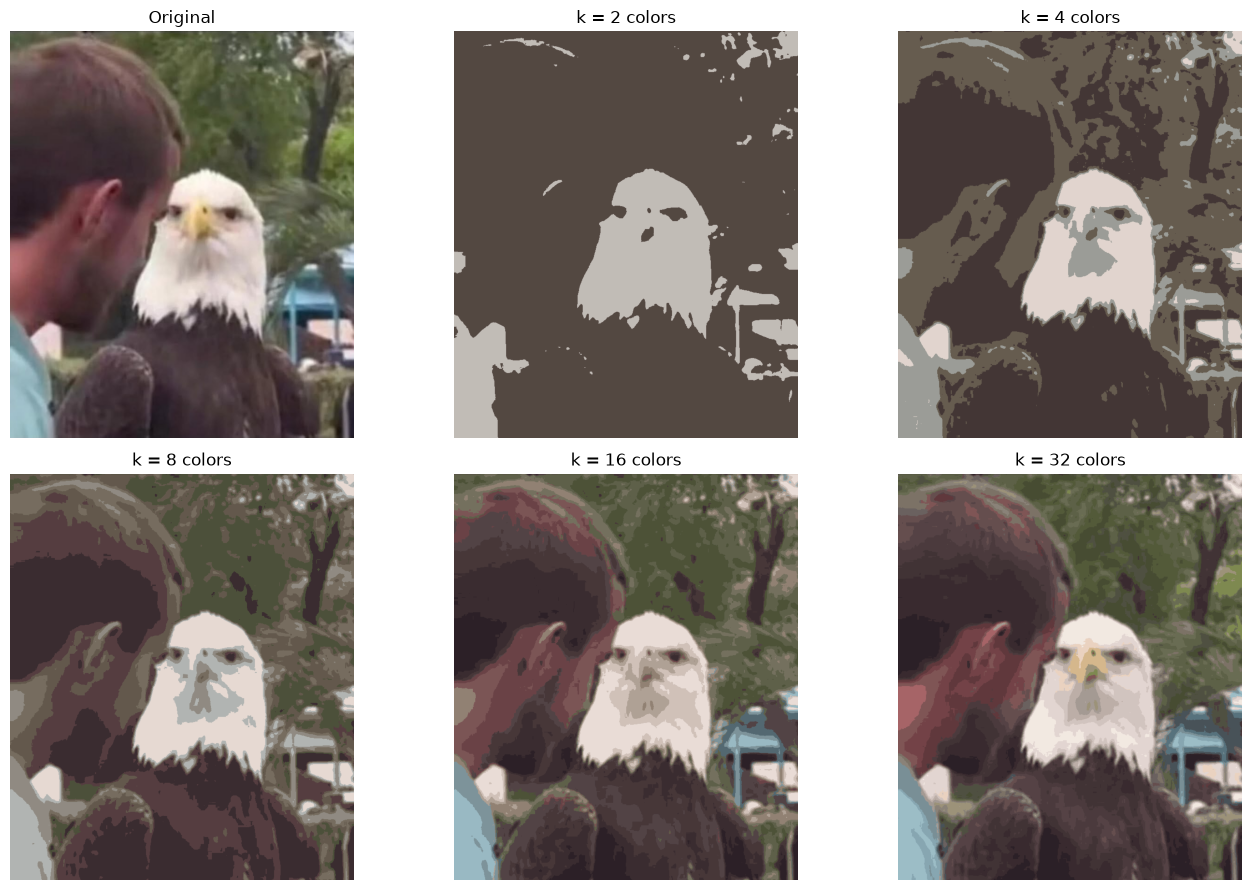

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, k in zip(axes[1:], k_values):
    ax.imshow(quantized_images[k])
    ax.set_title(f"k = {k} colors")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Cell 6 — Record Your Choice

This final cell is for your visual judgment. After comparing the plots, set `chosen_k` to the smallest value that still looks right to you. If none of the tested values is acceptable, add a larger value to `k_values` in Cell 4 and rerun Cells 4–6.

My chosen minimum k is 16 colors.


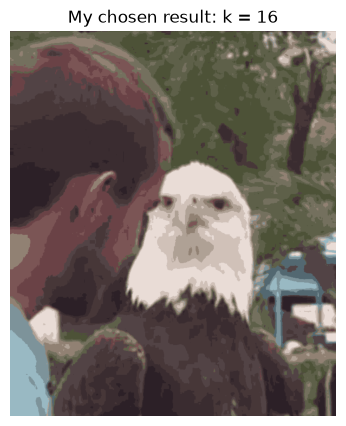

In [13]:
# Change this after inspecting the displayed images.
chosen_k = 16

if chosen_k not in quantized_images:
    print("chosen_k is not in the tested values. Add it to k_values and rerun Cell 4.")
else:
    print(f"My chosen minimum k is {chosen_k} colors.")
    plt.figure(figsize=(7, 5))
    plt.imshow(quantized_images[chosen_k])
    plt.title(f"My chosen result: k = {chosen_k}")
    plt.axis("off")
    plt.show()

## Final Answer 

### My Answer

I tested color quantization using 2, 4, 8, 16, and 32 colors. With 16 colors, the eagle remains recognizable and enough visual details are preserved. With fewer colors, some important details are lost. Therefore, I chose k = 16 as a good balance between image quality and the number of colors.